In [1]:
PROJECT_RANDOM_STATE = 2627
print("PROJECT_RANDOM_STATE =", PROJECT_RANDOM_STATE)

PROJECT_RANDOM_STATE = 2627


# Practice 2 — Challenge B: Storage

**Machine Learning — 2026/2027**

This notebook contains the complete Challenge B route required in Practice 2. The team-generated grouped protocol is built and frozen first; after P2.2(f), all scored development results use the course-owned canonical fold assignment.

In [2]:
from pathlib import Path
import subprocess
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupKFold, KFold, cross_validate
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

PROJECT_DIR = Path(".")
STORAGE_DIR = PROJECT_DIR / "datos" / "storage"
FOLDS_DIR = PROJECT_DIR / "folds"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

STORAGE_DEVELOPMENT_FILE = STORAGE_DIR / "storage_development.csv"
STORAGE_GROUPS_FILE = STORAGE_DIR / "storage_groups.csv"
STORAGE_CANONICAL_FOLDS_FILE = FOLDS_DIR / "storage_folds.csv"
VALIDATOR_FILE = PROJECT_DIR / "herramientas" / "validate_submission.py"

## P2.1 — Data contract and exploration

We verify the fixed Storage schema, count distinct configurations, and report the replicate count per configuration. `config_group` is split metadata only and is never an estimator feature.

In [3]:
storage = pd.read_csv(STORAGE_DEVELOPMENT_FILE)
storage_groups = pd.read_csv(STORAGE_GROUPS_FILE)

NOMINAL_FEATURES = ["load_type", "io_type", "raid", "device_type"]
NUMERIC_FEATURES = ["block_size", "n_jobs", "iodepth", "read_fraction", "n_disks"]
MODEL_FEATURES = NUMERIC_FEATURES + NOMINAL_FEATURES

EXPECTED_DEVELOPMENT_COLUMNS = [
    "row_id", "block_size", "n_jobs", "iodepth", "read_fraction",
    "load_type", "io_type", "raid", "n_disks", "device_type", "latency_ns",
]
EXPECTED_GROUP_COLUMNS = ["row_id", "config_group"]

assert list(storage.columns) == EXPECTED_DEVELOPMENT_COLUMNS
assert list(storage_groups.columns) == EXPECTED_GROUP_COLUMNS
assert storage["row_id"].is_unique
assert storage_groups["row_id"].is_unique
assert set(storage["row_id"]) == set(storage_groups["row_id"])

replicate_counts = storage_groups["config_group"].value_counts().sort_index()
print("Development shape:", storage.shape)
print("Distinct config_group values:", storage_groups["config_group"].nunique())
print("Replicate-count values:", sorted(replicate_counts.unique()))
print("Minimum replicates per configuration:", replicate_counts.min())
print("Maximum replicates per configuration:", replicate_counts.max())

Development shape: (12190, 11)
Distinct config_group values: 2438
Replicate-count values: [np.int64(5)]
Minimum replicates per configuration: 5
Maximum replicates per configuration: 5


### P2.1 result

The Storage development table contains 12,190 rows and nine model predictors. There are 2,438 distinct `config_group` values, and every configuration has exactly five replicate measurements. The five replicates of one configuration must therefore move together through the grouped evaluation protocol.

## P2.2(a) — Construct our five-fold grouped protocol

Challenge B uses `GroupKFold(n_splits=5)` with `config_group` as the grouping key. This splitter is deterministic here, so the project random state is not passed to it.

In [4]:
storage_all = storage.merge(storage_groups, on="row_id", how="left", validate="one_to_one")
X_storage = storage_all[MODEL_FEATURES]
y_storage_raw = storage_all["latency_ns"].to_numpy()
groups_storage = storage_all["config_group"]

cv_grouped = GroupKFold(n_splits=5)
own_fold_id = np.empty(len(storage_all), dtype=int)
fold_sizes = []

for q, (train_idx, valid_idx) in enumerate(
    cv_grouped.split(X_storage, y_storage_raw, groups=groups_storage),
    start=1,
):
    own_fold_id[valid_idx] = q
    fold_sizes.append({
        "fold": q,
        "train_rows": len(train_idx),
        "validation_rows": len(valid_idx),
    })

own_storage_folds = pd.DataFrame({
    "row_id": storage_all["row_id"],
    "fold_id": own_fold_id,
})
display(pd.DataFrame(fold_sizes))

,fold,train_rows,validation_rows
0,1,9750,2440
1,2,9750,2440
2,3,9750,2440
3,4,9755,2435
4,5,9755,2435


## P2.2(b) — Verify the configuration invariant

The Storage invariant is that all five replicate measurements of one configuration remain in the same fold. Equivalently, no `config_group` may appear in both the training and validation portions of a grouped round.

In [5]:
grouped_invariant_rows = []
for q, (train_idx, valid_idx) in enumerate(
    cv_grouped.split(X_storage, y_storage_raw, groups=groups_storage),
    start=1,
):
    train_groups = set(groups_storage.iloc[train_idx])
    valid_groups = set(groups_storage.iloc[valid_idx])
    overlap = train_groups.intersection(valid_groups)
    grouped_invariant_rows.append({
        "fold": q,
        "shared_config_groups": len(overlap),
        "invariant_holds": len(overlap) == 0,
    })

grouped_invariant_report = pd.DataFrame(grouped_invariant_rows)
display(grouped_invariant_report)
assert grouped_invariant_report["invariant_holds"].all()

cv_rowwise = KFold(n_splits=5, shuffle=True, random_state=PROJECT_RANDOM_STATE)
rowwise_overlap_rows = []
for q, (train_idx, valid_idx) in enumerate(cv_rowwise.split(X_storage), start=1):
    train_groups = set(groups_storage.iloc[train_idx])
    valid_groups = set(groups_storage.iloc[valid_idx])
    rowwise_overlap_rows.append({
        "fold": q,
        "shared_config_groups": len(train_groups.intersection(valid_groups)),
    })
display(pd.DataFrame(rowwise_overlap_rows))

,fold,shared_config_groups,invariant_holds
0,1,0,True
1,2,0,True
2,3,0,True
3,4,0,True
4,5,0,True


,fold,shared_config_groups
0,1,1654
1,2,1643
2,3,1610
3,4,1613
4,5,1641


### P2.2(b) interpretation

The grouped protocol keeps every configuration intact, so the overlap is zero in every fold. Ordinary row-wise K-fold has no knowledge of replicate membership and splits many configurations across training and validation. That makes the validation rows much less independent of the fitted data than the intended deployment question requires.

## P2.2(c) — Grouped versus row-wise evaluation

The course-fixed demonstration uses `KNeighborsRegressor(n_neighbors=5)`, one-hot encoding for the four nominal predictors, standardisation for the five numeric predictors, and MAE on `z = log10(latency_ns)`. Only the splitting protocol changes.

In [6]:
def make_storage_pipeline(n_neighbors):
    preprocessing = ColumnTransformer([
        ("nominal", OneHotEncoder(handle_unknown="ignore"), NOMINAL_FEATURES),
        ("numeric", StandardScaler(), NUMERIC_FEATURES),
    ])
    return Pipeline([
        ("preprocess", preprocessing),
        ("knn", KNeighborsRegressor(n_neighbors=n_neighbors)),
    ])

y_storage_z = np.log10(y_storage_raw)
comparison_pipeline = make_storage_pipeline(5)

grouped_result = cross_validate(
    comparison_pipeline,
    X_storage,
    y_storage_z,
    groups=groups_storage,
    cv=cv_grouped,
    scoring="neg_mean_absolute_error",
    n_jobs=1,
)
grouped_mae = -grouped_result["test_score"]

rowwise_result = cross_validate(
    comparison_pipeline,
    X_storage,
    y_storage_z,
    cv=cv_rowwise,
    scoring="neg_mean_absolute_error",
    n_jobs=1,
)
rowwise_mae = -rowwise_result["test_score"]

split_comparison = pd.DataFrame({
    "fold": np.arange(1, 6),
    "grouped_MAE_z": grouped_mae,
    "rowwise_MAE_z": rowwise_mae,
})
display(split_comparison.round(6))
print("Grouped mean MAE(z) :", f"{grouped_mae.mean():.6f}")
print("Row-wise mean MAE(z):", f"{rowwise_mae.mean():.6f}")
print("Grouped - row-wise  :", f"{grouped_mae.mean() - rowwise_mae.mean():+.6f}")

,fold,grouped_MAE_z,rowwise_MAE_z
0,1,0.205096,0.080536
1,2,0.206906,0.079069
2,3,0.206359,0.083843
3,4,0.209742,0.085751
4,5,0.217617,0.075395


Grouped mean MAE(z) : 0.209144
Row-wise mean MAE(z): 0.080919
Grouped - row-wise  : +0.128225


### P2.2(c) interpretation

The row-wise MAE is substantially smaller than the grouped MAE. Under row-wise K-fold, replicate measurements from the same storage configuration can appear in both training and validation. KNN can then evaluate a validation replicate against neighbours from the same configuration, making the task much easier than generalising to an unseen configuration. GroupKFold removes that source of optimism by keeping each complete `config_group` on one side of every fold.

## P2.2(f) — Freeze our construction and compare with the canonical folds

The team-generated construction and invariant report above are frozen before the released course-owned assignment is read.

In [7]:
canonical_folds = pd.read_csv(STORAGE_CANONICAL_FOLDS_FILE)
assert list(canonical_folds.columns) == ["row_id", "fold_id"]
assert canonical_folds["row_id"].is_unique
assert set(canonical_folds["row_id"]) == set(own_storage_folds["row_id"])
assert set(canonical_folds["fold_id"]) == {0, 1, 2, 3, 4}

fold_comparison = own_storage_folds.merge(
    canonical_folds,
    on="row_id",
    how="inner",
    suffixes=("_ours", "_canonical"),
    validate="one_to_one",
)
display(pd.crosstab(
    fold_comparison["fold_id_ours"],
    fold_comparison["fold_id_canonical"],
    rownames=["our fold id"],
    colnames=["canonical fold id"],
))

same_after_label_normalisation = (
    fold_comparison["fold_id_ours"] - 1
    == fold_comparison["fold_id_canonical"]
)
print("Agreement after converting our 1..5 labels to 0..4:", f"{same_after_label_normalisation.mean():.4f}")
assert same_after_label_normalisation.all()

canonical fold id,0,1,2,3,4
our fold id,,,,,
1,2440,0,0,0,0
2,0,2440,0,0,0
3,0,0,2440,0,0
4,0,0,0,2435,0
5,0,0,0,0,2435


Agreement after converting our 1..5 labels to 0..4: 1.0000


### P2.2(f) interpretation

The partitions are identical; only the numeric labels differ. Our loop used fold labels 1–5, while the canonical sidecar uses 0–4. Subtracting one from our labels produces exact row-by-row agreement.

## P2.2(g) — Adopt the canonical assignment

Every scored development result from this point uses the released `storage_folds.csv` assignment.

In [8]:
canonical_folds = storage[["row_id"]].merge(
    canonical_folds,
    on="row_id",
    how="left",
    validate="one_to_one",
)
canonical_fold_id = canonical_folds["fold_id"].to_numpy()
CANONICAL_FOLD_VALUES = sorted(canonical_folds["fold_id"].unique())
canonical_cv = []
canonical_checks = []

for fold_id in CANONICAL_FOLD_VALUES:
    valid_idx = np.flatnonzero(canonical_fold_id == fold_id)
    train_idx = np.flatnonzero(canonical_fold_id != fold_id)
    canonical_cv.append((train_idx, valid_idx))
    overlap = set(groups_storage.iloc[train_idx]).intersection(set(groups_storage.iloc[valid_idx]))
    canonical_checks.append({
        "fold_id": fold_id,
        "train_rows": len(train_idx),
        "validation_rows": len(valid_idx),
        "shared_config_groups": len(overlap),
    })

canonical_check_report = pd.DataFrame(canonical_checks)
display(canonical_check_report)
assert (canonical_check_report["shared_config_groups"] == 0).all()

,fold_id,train_rows,validation_rows,shared_config_groups
0,0,9750,2440,0
1,1,9750,2440,0
2,2,9750,2440,0
3,3,9755,2435,0
4,4,9755,2435,0


## P2.3 — Guided target-representation discovery

We first inspect the raw positive latency distribution. Then, on exactly the same canonical folds, we fit only the two required raw-target models — a mean `DummyRegressor` and KNN with `K_NN=5` — and refit those same two models after defining `z = log10(latency_ns)`.

In [9]:
latency_summary = storage["latency_ns"].describe(percentiles=[0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.99])
display(latency_summary.to_frame("latency_ns"))
print("Minimum latency_ns:", f"{y_storage_raw.min():.3f}")
print("Maximum latency_ns:", f"{y_storage_raw.max():.3f}")
print("max / min ratio:", f"{y_storage_raw.max() / y_storage_raw.min():.2f}")
print("log10 range:", f"{np.log10(y_storage_raw.min()):.3f} to {np.log10(y_storage_raw.max()):.3f}")

,latency_ns
count,1.219000e+04
mean,2.746043e+07
std,1.103979e+08
min,1.160660e+05
1%,1.605750e+05
10%,3.449549e+05
25%,5.864854e+05
50%,1.183157e+06
75%,6.983904e+06
90%,4.752643e+07


Minimum latency_ns: 116066.000
Maximum latency_ns: 2533493118.350
max / min ratio: 21828.04
log10 range: 5.065 to 9.404


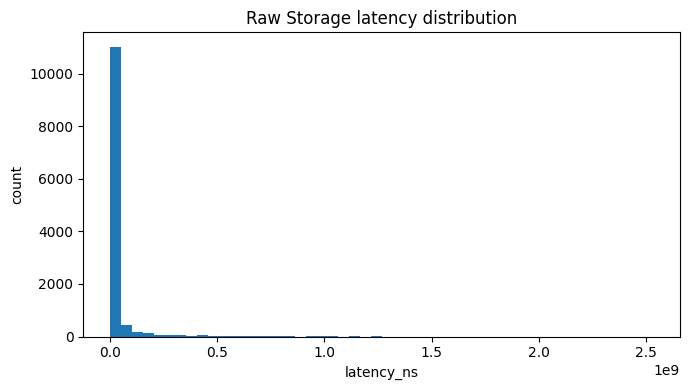

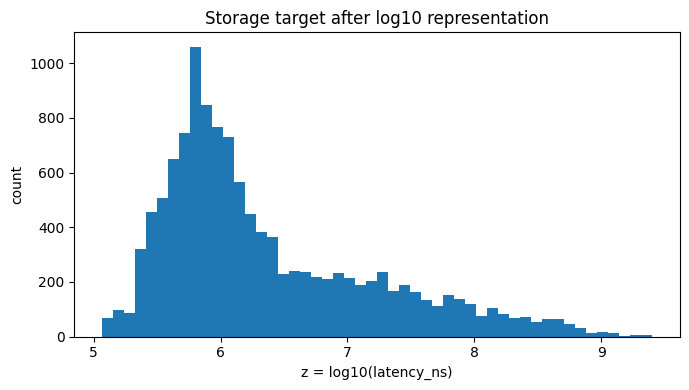

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(y_storage_raw, bins=50)
ax.set_xlabel("latency_ns")
ax.set_ylabel("count")
ax.set_title("Raw Storage latency distribution")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(y_storage_z, bins=50)
ax.set_xlabel("z = log10(latency_ns)")
ax.set_ylabel("count")
ax.set_title("Storage target after log10 representation")
plt.tight_layout()
plt.show()

In [11]:
def evaluate_p23_model(model_name, target_name, target_values, model_factory):
    fold_mae = []
    for fold_id, (train_idx, valid_idx) in zip(CANONICAL_FOLD_VALUES, canonical_cv):
        model = model_factory()
        model.fit(X_storage.iloc[train_idx], target_values[train_idx])
        prediction = model.predict(X_storage.iloc[valid_idx])
        fold_mae.append(mean_absolute_error(target_values[valid_idx], prediction))
    return {
        "target": target_name,
        "model": model_name,
        "fold_0": fold_mae[0],
        "fold_1": fold_mae[1],
        "fold_2": fold_mae[2],
        "fold_3": fold_mae[3],
        "fold_4": fold_mae[4],
        "mean_MAE": np.mean(fold_mae),
    }

p23_rows = []
p23_rows.append(evaluate_p23_model(
    "DummyRegressor(mean)", "raw latency_ns", y_storage_raw,
    lambda: DummyRegressor(strategy="mean"),
))
p23_rows.append(evaluate_p23_model(
    "KNN(5)", "raw latency_ns", y_storage_raw,
    lambda: make_storage_pipeline(5),
))
p23_rows.append(evaluate_p23_model(
    "DummyRegressor(mean)", "z = log10(latency_ns)", y_storage_z,
    lambda: DummyRegressor(strategy="mean"),
))
p23_rows.append(evaluate_p23_model(
    "KNN(5)", "z = log10(latency_ns)", y_storage_z,
    lambda: make_storage_pipeline(5),
))

p23_report = pd.DataFrame(p23_rows)
display(p23_report)

,target,model,fold_0,fold_1,fold_2,fold_3,fold_4,mean_MAE
0,raw latency_ns,DummyRegressor(mean),4.360498e+07,4.306579e+07,4.276686e+07,3.973807e+07,4.138798e+07,4.211274e+07
1,raw latency_ns,KNN(5),1.923132e+07,1.652580e+07,1.761602e+07,1.626782e+07,2.001799e+07,1.793179e+07
2,z = log10(latency_ns),DummyRegressor(mean),6.799929e-01,6.778127e-01,6.627650e-01,6.722045e-01,6.921728e-01,6.769896e-01
3,z = log10(latency_ns),KNN(5),2.050962e-01,2.069065e-01,2.063595e-01,2.097418e-01,2.176166e-01,2.091441e-01


### P2.3 justification carried forward to the defence pack

`latency_ns` is strictly positive and spans more than four orders of magnitude in the development data. On the raw scale, an absolute error of the same relative size is numerically far larger for a high-latency configuration than for a low-latency configuration, so raw-scale MAE gives the largest latencies much more influence simply because of their units and magnitude. The raw histogram and quantiles show that this is a strongly right-skewed target rather than a narrow additive-error problem.

We therefore adopt `z = log10(latency_ns)` as the modelling target. The transformation preserves the ordering of positive latency values but changes the loss currency: differences in `z` correspond to multiplicative differences on the physical scale, so comparable proportional errors have comparable importance across low- and high-latency configurations. This decision is justified by the scale and structure of the engineering target, not by choosing whichever of the four demonstration numbers happens to look best. From this point onward, the primary Storage metric is MAE computed directly on `z` and `z_hat`.

For any physical-scale metric, predictions are first inverted as `latency_ns_hat = 10 ** z_hat` and only then compared with the raw `latency_ns`. We never exponentiate MAE(z) and call the result a nanosecond error.

## P2.4 — Baseline and nearest neighbours on the canonical folds

The regression baseline is `DummyRegressor(strategy="mean")` on the adopted `z` target. For KNN we use the same compact predeclared neighbour grid used in the Unit 5 model-selection notebook. The primary metric is MAE(z), so smaller is better.

**Scaling decision.** Euclidean neighbourhoods are scale-dependent. The five numeric predictors are standardised inside each fold; the four nominal predictors are one-hot encoded. No group or fold metadata enters the estimator.

In [12]:
N_NEIGHBOURS_GRID = [1, 3, 5, 7, 9, 11, 15, 21, 31]

knn_curve_rows = []
knn_fold_scores = {}
for n_neighbours in N_NEIGHBOURS_GRID:
    result = cross_validate(
        make_storage_pipeline(n_neighbours),
        X_storage,
        y_storage_z,
        cv=canonical_cv,
        scoring="neg_mean_absolute_error",
        n_jobs=1,
    )
    fold_mae = -result["test_score"]
    knn_fold_scores[n_neighbours] = fold_mae
    knn_curve_rows.append({
        "K_NN": n_neighbours,
        "mean_MAE_z": fold_mae.mean(),
        "sd_across_folds": fold_mae.std(ddof=0),
        "range_across_folds": fold_mae.max() - fold_mae.min(),
        "min_fold": fold_mae.min(),
        "max_fold": fold_mae.max(),
    })

knn_curve = pd.DataFrame(knn_curve_rows)
display(knn_curve.round(6))
best_index = knn_curve["mean_MAE_z"].idxmin()
selected_neighbours = int(knn_curve.loc[best_index, "K_NN"])
print("Selected K_NN:", selected_neighbours)
print("Best mean canonical MAE(z):", f"{knn_curve.loc[best_index, 'mean_MAE_z']:.6f}")

,K_NN,mean_MAE_z,sd_across_folds,range_across_folds,min_fold,max_fold
0,1,0.211237,0.004927,0.013713,0.206548,0.220261
1,3,0.209992,0.003750,0.010249,0.207098,0.217348
2,5,0.209144,0.004501,0.012520,0.205096,0.217617
3,7,0.183334,0.003278,0.008897,0.178492,0.187388
4,9,0.182245,0.003308,0.007126,0.178197,0.185323
5,11,0.178491,0.003238,0.007034,0.174231,0.181265
6,15,0.180087,0.002713,0.007771,0.174825,0.182596
7,21,0.179006,0.004192,0.011291,0.175002,0.186293
8,31,0.182624,0.005478,0.013923,0.176278,0.190201


Selected K_NN: 11
Best mean canonical MAE(z): 0.178491


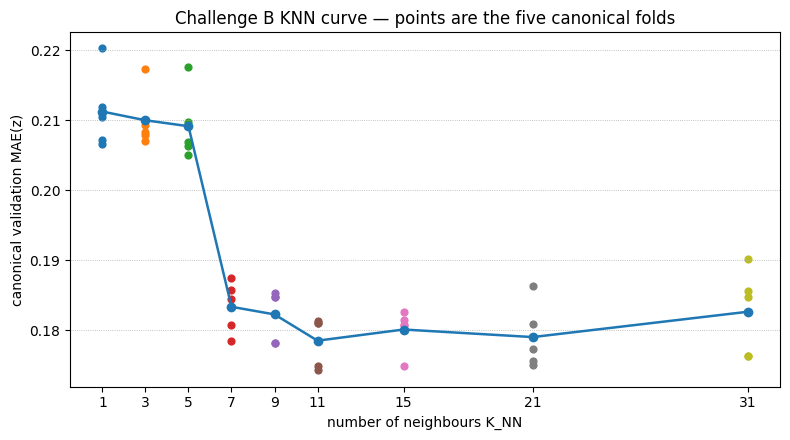

In [13]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for n_neighbours, fold_mae in knn_fold_scores.items():
    ax.scatter([n_neighbours] * len(fold_mae), fold_mae, s=24)
ax.plot(knn_curve["K_NN"], knn_curve["mean_MAE_z"], marker="o", linewidth=1.8)
ax.set_xticks(N_NEIGHBOURS_GRID)
ax.set_xlabel("number of neighbours K_NN")
ax.set_ylabel("canonical validation MAE(z)")
ax.set_title("Challenge B KNN curve — points are the five canonical folds")
ax.grid(axis="y", linestyle=":", linewidth=0.6)
plt.tight_layout()
plt.show()

In [14]:
def evaluate_storage_family(family_name, model_factory):
    rows = []
    for fold_id, (train_idx, valid_idx) in zip(CANONICAL_FOLD_VALUES, canonical_cv):
        model = model_factory()
        start = time.perf_counter()
        model.fit(X_storage.iloc[train_idx], y_storage_z[train_idx])
        fit_time = time.perf_counter() - start
        pred_z = model.predict(X_storage.iloc[valid_idx])
        pred_ns = 10 ** pred_z
        rows.append({
            "fold_id": fold_id,
            "MAE_z": mean_absolute_error(y_storage_z[valid_idx], pred_z),
            "RMSE_z": np.sqrt(mean_squared_error(y_storage_z[valid_idx], pred_z)),
            "R2_z": r2_score(y_storage_z[valid_idx], pred_z),
            "MAE_ns": mean_absolute_error(y_storage_raw[valid_idx], pred_ns),
            "fit_time_s": fit_time,
        })
    result = pd.DataFrame(rows)
    print(family_name)
    display(result.round(6))
    print("Mean MAE(z):", f"{result['MAE_z'].mean():.6f}")
    print("Mean RMSE(z):", f"{result['RMSE_z'].mean():.6f}")
    print("Mean R2(z):", f"{result['R2_z'].mean():.6f}")
    print("Mean MAE_ns:", f"{result['MAE_ns'].mean():.3f}")
    return result

dummy_metrics = evaluate_storage_family(
    "DummyRegressor(strategy='mean')",
    lambda: DummyRegressor(strategy="mean"),
)
selected_metrics = evaluate_storage_family(
    f"KNeighborsRegressor(n_neighbors={selected_neighbours})",
    lambda: make_storage_pipeline(selected_neighbours),
)

DummyRegressor(strategy='mean')


,fold_id,MAE_z,RMSE_z,R2_z,MAE_ns,fit_time_s
0,0,0.679993,0.844457,-0.000153,2.839968e+07,0.015585
1,1,0.677813,0.843639,-0.000176,2.854142e+07,0.018312
2,2,0.662765,0.833118,-0.000097,2.742680e+07,0.005663
3,3,0.672204,0.826908,-0.000116,2.407004e+07,0.003939
4,4,0.692173,0.851699,-0.000000,2.674962e+07,0.013339


Mean MAE(z): 0.676990
Mean RMSE(z): 0.839964
Mean R2(z): -0.000108
Mean MAE_ns: 27037510.970


KNeighborsRegressor(n_neighbors=11)


,fold_id,MAE_z,RMSE_z,R2_z,MAE_ns,fit_time_s
0,0,0.181265,0.263833,0.902373,1.660935e+07,0.147447
1,1,0.174836,0.242933,0.917066,1.623663e+07,0.100984
2,2,0.174231,0.249869,0.910039,1.555760e+07,0.092296
3,3,0.181037,0.255199,0.904743,1.430623e+07,0.031536
4,4,0.181084,0.276544,0.894572,1.758354e+07,0.057970


Mean MAE(z): 0.178491
Mean RMSE(z): 0.257676
Mean R2(z): 0.905759
Mean MAE_ns: 16058670.652


### P2.4 interpretation

The whole neighbour curve is reported above. The selected KNN is the candidate with the smallest mean canonical MAE(z), not a value chosen from a single fold. It strongly improves over the mean DummyRegressor on MAE(z), RMSE(z), R2(z), and the separately computed physical-scale MAE in nanoseconds. The physical MAE was obtained by inverting each prediction first; it is not `10 ** MAE(z)`.

## P2.6 — Storage submission-format dry run and basis declaration

We imitate a final-test feature table with one canonical development fold. The selected model is fitted on the other four folds, predicts `z`, and those predictions are inverted to the required physical `latency_ns` column before the supplied format validator is run.

In [15]:
dry_fold_id = CANONICAL_FOLD_VALUES[0]
dry_valid_idx = np.flatnonzero(canonical_fold_id == dry_fold_id)
dry_train_idx = np.flatnonzero(canonical_fold_id != dry_fold_id)

dry_model = make_storage_pipeline(selected_neighbours)
dry_model.fit(X_storage.iloc[dry_train_idx], y_storage_z[dry_train_idx])
dry_prediction_z = dry_model.predict(X_storage.iloc[dry_valid_idx])
dry_prediction_ns = 10 ** dry_prediction_z

assert np.isfinite(dry_prediction_ns).all()
assert (dry_prediction_ns > 0).all()

dry_features = storage.iloc[dry_valid_idx][["row_id"] + MODEL_FEATURES].copy()
dry_submission = pd.DataFrame({
    "row_id": storage.iloc[dry_valid_idx]["row_id"].to_numpy(),
    "latency_ns": dry_prediction_ns,
})

dry_features_file = OUTPUT_DIR / "storage_dry_run_features.csv"
dry_submission_file = OUTPUT_DIR / "storage_submission_dry_run.csv"
dry_features.to_csv(dry_features_file, index=False)
dry_submission.to_csv(dry_submission_file, index=False)

validator = subprocess.run(
    [
        sys.executable,
        str(VALIDATOR_FILE),
        "storage",
        str(dry_submission_file),
        str(dry_features_file),
    ],
    capture_output=True,
    text=True,
)
print("Validator output:", validator.stdout.strip())
if validator.stderr.strip():
    print("Validator stderr:", validator.stderr.strip())
assert validator.returncode == 0
assert validator.stdout.strip() == "valid"
print("Minimum submitted latency_ns:", dry_submission["latency_ns"].min())
print("Maximum submitted latency_ns:", dry_submission["latency_ns"].max())
display(dry_submission.head())

Validator output: valid
Minimum submitted latency_ns: 127549.93929857158
Maximum submitted latency_ns: 966144421.2582119


,row_id,latency_ns
0,S00010,4.847099e+07
1,S00011,4.847099e+07
2,S00012,4.847099e+07
3,S00013,4.847099e+07
4,S00014,4.847099e+07


### Frozen predictive-information basis — Challenge B

The primary Storage basis is the nine distributed source predictors: `block_size`, `n_jobs`, `iodepth`, `read_fraction`, `load_type`, `io_type`, `raid`, `n_disks`, and `device_type`. `row_id`, `config_group`, and `fold_id` are never estimator inputs. The target representation `z = log10(latency_ns)` is frozen from P2.3 onward. One-hot encoding and method-required numeric scaling are representation choices that add no new predictive information.

In [16]:
def score_string(values):
    return " ".join(f"{value:.6f}" for value in values)

storage_comparison_rows = pd.DataFrame([
    {
        "milestone": "P2",
        "challenge": "storage",
        "family": "Dummy",
        "route": "primary",
        "configuration": "strategy=mean; target z=log10(latency_ns)",
        "preprocessing": "none (baseline ignores X); target z",
        "features": "features.md: 9 distributed source predictors (frozen basis)",
        "validation": "canonical GroupKFold(5) on config_group, read from storage_folds.csv",
        "primary_metric_per_fold": score_string(dummy_metrics["MAE_z"]),
        "primary_metric": f"{dummy_metrics['MAE_z'].mean():.6f}",
        "primary_metric_spread": f"range={dummy_metrics['MAE_z'].max() - dummy_metrics['MAE_z'].min():.6f}",
        "supporting_metrics": f"mean RMSE(z)={dummy_metrics['RMSE_z'].mean():.6f}; mean R2(z)={dummy_metrics['R2_z'].mean():.6f}; mean MAE_ns={dummy_metrics['MAE_ns'].mean():.3f}",
        "fit_time_s": f"{dummy_metrics['fit_time_s'].sum():.6f} total CV fit time",
        "interpretability": "none",
        "notes": "Establishes the mean-target baseline without reading predictor values.",
    },
    {
        "milestone": "P2",
        "challenge": "storage",
        "family": "KNN",
        "route": "primary",
        "configuration": f"KNeighborsRegressor(n_neighbors={selected_neighbours}); target z=log10(latency_ns)",
        "preprocessing": "one-hot nominal; StandardScaler numeric; fitted inside each fold; target z",
        "features": "features.md: 9 distributed source predictors (frozen basis)",
        "validation": "canonical GroupKFold(5) on config_group, read from storage_folds.csv",
        "primary_metric_per_fold": score_string(selected_metrics["MAE_z"]),
        "primary_metric": f"{selected_metrics['MAE_z'].mean():.6f}",
        "primary_metric_spread": f"range={selected_metrics['MAE_z'].max() - selected_metrics['MAE_z'].min():.6f}",
        "supporting_metrics": f"mean RMSE(z)={selected_metrics['RMSE_z'].mean():.6f}; mean R2(z)={selected_metrics['R2_z'].mean():.6f}; mean MAE_ns={selected_metrics['MAE_ns'].mean():.3f}",
        "fit_time_s": f"{selected_metrics['fit_time_s'].sum():.6f} total CV fit time",
        "interpretability": "none",
        "notes": "Uses local neighbourhood structure and strongly improves on the mean baseline.",
    },
])
display(storage_comparison_rows)
storage_comparison_rows.to_csv(OUTPUT_DIR / "comparativa_p2_storage.csv", index=False)

,milestone,challenge,family,route,configuration,preprocessing,features,validation,primary_metric_per_fold,primary_metric,primary_metric_spread,supporting_metrics,fit_time_s,interpretability,notes
0,P2,storage,Dummy,primary,strategy=mean; target z=log10(latency_ns),none (baseline ignores X); target z,features.md: 9 distributed source predictors (...,"canonical GroupKFold(5) on config_group, read ...",0.679993 0.677813 0.662765 0.672204 0.692173,0.676990,range=0.029408,mean RMSE(z)=0.839964; mean R2(z)=-0.000108; m...,0.056839 total CV fit time,none,Establishes the mean-target baseline without r...
1,P2,storage,KNN,primary,KNeighborsRegressor(n_neighbors=11); target z=...,one-hot nominal; StandardScaler numeric; fitte...,features.md: 9 distributed source predictors (...,"canonical GroupKFold(5) on config_group, read ...",0.181265 0.174836 0.174231 0.181037 0.181084,0.178491,range=0.007034,mean RMSE(z)=0.257676; mean R2(z)=0.905759; me...,0.430233 total CV fit time,none,Uses local neighbourhood structure and strongl...


## Challenge B completion check

- P2.1 data contract, configuration count and replicate count: complete.
- P2.2 own grouped construction, invariant, split-protocol comparison, freeze, canonical comparison and adoption: complete.
- P2.3 bounded raw-versus-log target-representation exercise and written justification: complete.
- P2.4 baseline, full KNN curve, selected model and full Storage metric contract: complete.
- P2.6 Storage dry run, inverse transformation, validator check, basis declaration and comparison rows: complete.

P2.5 is a Challenge A probability exercise and is therefore contained only in the Cyber notebook.